<a href="https://colab.research.google.com/github/janepium/deteccion-anomalias-rt-iot/blob/main/notebooks/13_random_forest_multiclase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Semana 6 — Random Forest multiclase

**Responsable:** Daniel  
**Objetivo:** clasificar el tráfico en las 12 categorías de `Attack_type`, evaluar el desempeño general y por clase, revisar la importancia de las variables y comparar inicialmente con la clasificación binaria.

> Se conserva la configuración de Random Forest de referencia de la clasificación binaria. En esta etapa no se realiza una búsqueda extensa de hiperparámetros. El conjunto Test se reserva para la evaluación final.

## 1. Importaciones y carga del dataset

El notebook busca `dataset_limpio.csv` en ubicaciones habituales del proyecto o en Colab. Si el archivo está en otra ubicación, añade esa ruta en `RUTAS_DATASET`.

In [ ]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RUTAS_DATASET = [
    Path("dataset_limpio.csv"),
    Path("dataset_limpio.csv"),
    Path("dataset_limpio.csv"),
    ]
DATA_PATH = next((ruta for ruta in RUTAS_DATASET if ruta.exists()), None)
if DATA_PATH is None:
    rutas = "\n".join(f"- {ruta}" for ruta in RUTAS_DATASET)
    raise FileNotFoundError(
        "No se encontró dataset_limpio.csv. Coloca el archivo en una de estas rutas:\n" + rutas
    )

df = pd.read_csv(DATA_PATH)
# Eliminar solo una columna índice guardada explícitamente como "Unnamed: 0".
if len(df.columns) and str(df.columns[0]).lower().startswith("unnamed:"):
    df = df.drop(columns=[df.columns[0]])

print(f"Dataset utilizado: {DATA_PATH.resolve()}")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")

# Salvaguarda: el experimento binario de referencia que se está continuando utilizó
# la versión de 62.338 registros. Ajusta esta constante solo si el equipo confirma
# formalmente una nueva versión del dataset.


display(df.head())

Dataset utilizado: /content/dataset_limpio.csv
Dimensiones: 117,922 filas × 37 columnas


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,flow_pkts_per_sec,down_up_ratio,...,fwd_iat.std,fwd_subflow_bytes,fwd_bulk_bytes,active.std,idle.tot,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,0.437341,0.555556,...,1.040307e+07,25.333333,0.0,0.0,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,0.439097,0.555556,...,1.046346e+07,25.333333,0.0,0.0,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,0.435811,0.555556,...,1.044238e+07,24.666667,0.0,0.0,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,0.438033,0.555556,...,1.048253e+07,24.666667,0.0,0.0,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,0.438839,0.555556,...,1.044702e+07,25.333333,0.0,0.0,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


## 2. Preparación de `X` y de la variable objetivo

Se utiliza `Attack_type` directamente como objetivo multiclase; no se construye `y_bin`. Se excluye `Attack_type` de los predictores y también las variables potencialmente *leaky*: `id.orig_p`, `id.resp_p`, `proto` y `service`. Se conservan las demás features del dataset limpio, respetando la eliminación previa de variables redundantes.

El bloque verifica que las features restantes sean numéricas y que existan 12 clases. Si falla una comprobación, revisa la ruta y la versión del dataset antes de continuar.

In [ ]:
if "Attack_type" not in df.columns:
    raise KeyError("El dataset debe contener la columna 'Attack_type'.")

LEAKY = ["id.orig_p", "id.resp_p", "proto", "service"]
missing_leaky = [col for col in LEAKY if col not in df.columns]
if missing_leaky:
    warnings.warn(f"Estas columnas leaky no aparecen en el dataset: {missing_leaky}")

X = df.drop(columns=["Attack_type"] + [c for c in LEAKY if c in df.columns]).copy()
y = df["Attack_type"].astype(str).copy()
non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric:
    raise TypeError(
        "Hay features no numéricas después de excluir las variables leaky: "
        f"{non_numeric}. Revisa el preprocesamiento."
    )

clases = sorted(y.unique().tolist())
print(f"Número de clases encontradas: {len(clases)}")
print(f"Número de features: {len(X.columns)}")
print("Variables leaky excluidas:", [c for c in LEAKY if c in df.columns])
print("Attack_type se utiliza solo como objetivo.")

if len(clases) != 12:
    raise ValueError(
        f"Se esperaban 12 clases en Attack_type, pero se encontraron {len(clases)}. "
        "Verifica que estás cargando el dataset correcto."
    )
print("\nClases detectadas:")
for clase in clases:
    print("-", clase)

Número de clases encontradas: 12
Número de features: 32
Variables leaky excluidas: ['id.orig_p', 'id.resp_p', 'proto', 'service']
Attack_type se utiliza solo como objetivo.

Clases detectadas:
- ARP_poisioning
- DDOS_Slowloris
- DOS_SYN_Hping
- MQTT_Publish
- Metasploit_Brute_Force_SSH
- NMAP_FIN_SCAN
- NMAP_OS_DETECTION
- NMAP_TCP_scan
- NMAP_UDP_SCAN
- NMAP_XMAS_TREE_SCAN
- Thing_Speak
- Wipro_bulb


## 3. Distribución de clases y división Train/Test

Se aplica una partición **80 % Train / 20 % Test**, con `stratify=y` y `random_state=42`. La estratificación intenta conservar la proporción de cada clase en ambos conjuntos. Debido al desbalance, se informa el soporte de cada clase para valorar con cautela las métricas de las categorías minoritarias.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

distribucion = pd.concat([
    y.value_counts().rename("Total"),
    y_train.value_counts().rename("Train"),
    y_test.value_counts().rename("Test"),
], axis=1).fillna(0).astype(int)
distribucion["Train (%)"] = (distribucion["Train"] / len(y_train) * 100).round(3)
distribucion["Test (%)"] = (distribucion["Test"] / len(y_test) * 100).round(3)
distribucion = distribucion.sort_values("Total", ascending=False)

display(distribucion)
print(f"\nTrain: {len(X_train):,} ({len(X_train)/len(df):.1%})")
print(f"Test:  {len(X_test):,} ({len(X_test)/len(df):.1%})")
print(f"Clases en Train: {y_train.nunique()} de {len(clases)}")
print(f"Clases en Test: {y_test.nunique()} de {len(clases)}")
assert set(y_train.unique()) == set(clases), "Hay clases ausentes en Train."
assert set(y_test.unique()) == set(clases), "Hay clases ausentes en Test."

,Total,Train,Test,Train (%),Test (%)
Attack_type,,,,,
DOS_SYN_Hping,90089,72071,18018,76.397,76.396
Thing_Speak,7654,6123,1531,6.491,6.491
ARP_poisioning,7625,6100,1525,6.466,6.466
MQTT_Publish,4142,3314,828,3.513,3.511
NMAP_UDP_SCAN,2584,2067,517,2.191,2.192
NMAP_XMAS_TREE_SCAN,2010,1608,402,1.705,1.704
NMAP_OS_DETECTION,2000,1600,400,1.696,1.696
NMAP_TCP_scan,1002,802,200,0.850,0.848
DDOS_Slowloris,533,426,107,0.452,0.454



Train: 94,337 (80.0%)
Test:  23,585 (20.0%)
Clases en Train: 12 de 12
Clases en Test: 12 de 12


## 4. Entrenamiento del Random Forest de referencia

Se conserva la configuración de la clasificación binaria: `n_estimators=100`, `class_weight="balanced"`, `random_state=42` y `n_jobs=-1`. Los pesos balanceados compensan parcialmente las diferencias de frecuencia entre las clases. Random Forest no requiere escalado de variables; no se ejecuta GridSearchCV en esta etapa.

In [ ]:
rf_multiclase = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

inicio = time.perf_counter()
rf_multiclase.fit(X_train, y_train)
tiempo_entrenamiento = time.perf_counter() - inicio

inicio = time.perf_counter()
y_pred = rf_multiclase.predict(X_test)
tiempo_prediccion = time.perf_counter() - inicio

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.3f} segundos")
print(f"Tiempo de predicción en Test: {tiempo_prediccion:.3f} segundos")

Tiempo de entrenamiento: 2.794 segundos
Tiempo de predicción en Test: 0.073 segundos


## 5. Métricas generales

Se calculan Accuracy, Precision macro, Recall macro, F1-Macro y F1-Weighted. Las métricas macro dan igual peso a cada categoría; F1-Weighted pondera cada clase según su soporte y, por tanto, se ve más influido por las clases frecuentes.

In [ ]:
metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}
tabla_metricas = pd.DataFrame(
    [{"Métrica": k, "Resultado": v} for k, v in metricas.items()]
)
display(tabla_metricas.style.format({"Resultado": "{:.6f}"}))

,Métrica,Resultado
0,Accuracy,0.996184
1,Precision macro,0.964506
2,Recall macro,0.987651
3,F1-Macro,0.974786
4,F1-Weighted,0.996212


## 6. Matriz de confusión multiclase

Las filas corresponden a las clases reales y las columnas a las predicciones. Los valores fuera de la diagonal muestran errores entre tipos de tráfico. También se presenta la matriz normalizada por clase real para comparar categorías con tamaños distintos.

Predicción,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
Real,,,,,,,,,,,,
ARP_poisioning,1475,0,0,0,1,0,0,0,39,0,10,0
DDOS_Slowloris,0,104,0,0,0,0,0,0,3,0,0,0
DOS_SYN_Hping,0,0,18018,0,0,0,0,0,0,0,0,0
MQTT_Publish,1,0,0,827,0,0,0,0,0,0,0,0
Metasploit_Brute_Force_SSH,0,0,0,0,7,0,0,0,0,0,0,0
NMAP_FIN_SCAN,0,0,0,0,0,6,0,0,0,0,0,0
NMAP_OS_DETECTION,0,0,0,0,0,0,400,0,0,0,0,0
NMAP_TCP_scan,0,0,0,0,0,0,0,200,0,0,0,0
NMAP_UDP_SCAN,1,9,0,0,0,0,0,0,504,0,3,0


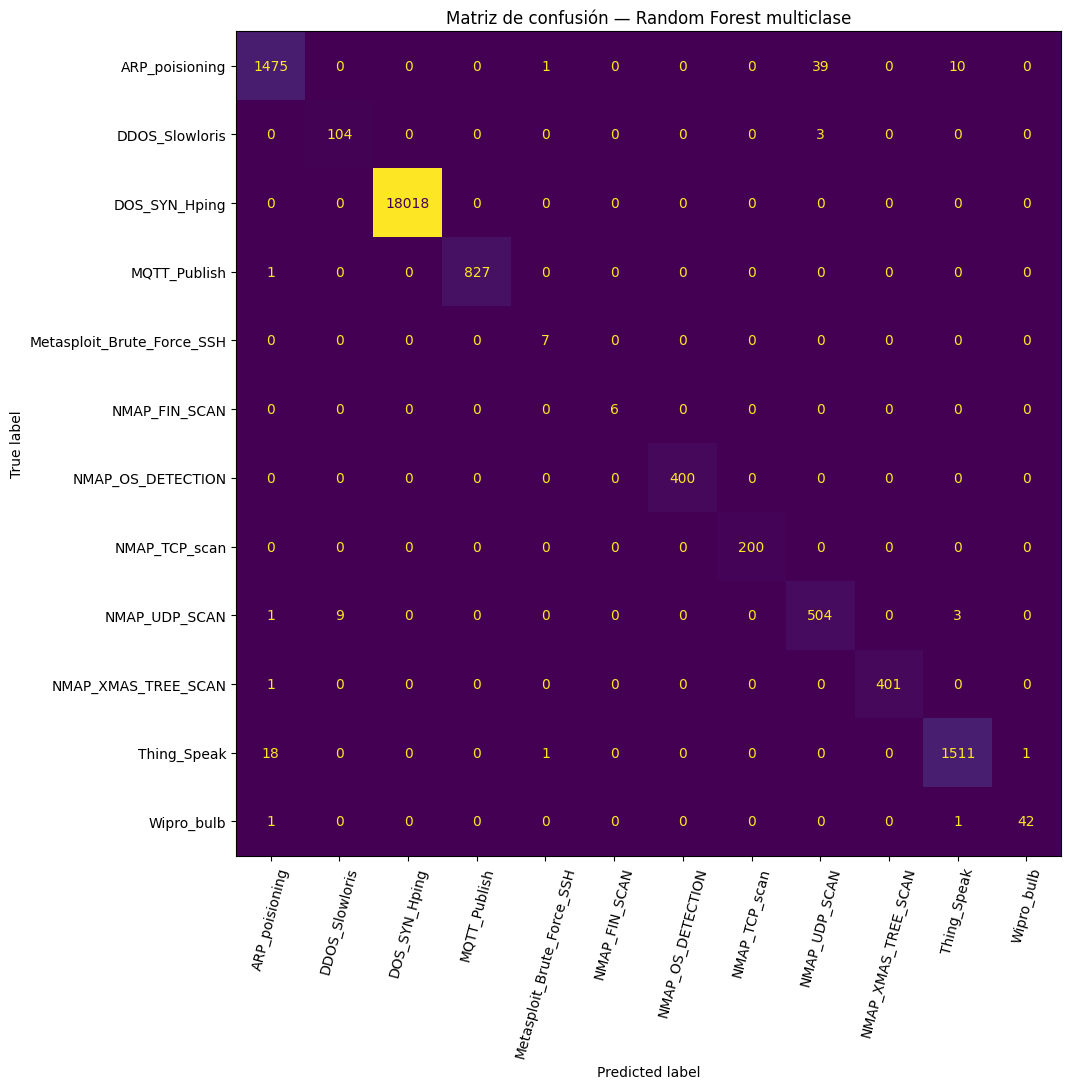

Matriz de confusión normalizada por clase real:


Predicción,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
Real,,,,,,,,,,,,
ARP_poisioning,0.967,0.000,0.0,0.000,0.001,0.0,0.0,0.0,0.026,0.000,0.007,0.000
DDOS_Slowloris,0.000,0.972,0.0,0.000,0.000,0.0,0.0,0.0,0.028,0.000,0.000,0.000
DOS_SYN_Hping,0.000,0.000,1.0,0.000,0.000,0.0,0.0,0.0,0.000,0.000,0.000,0.000
MQTT_Publish,0.001,0.000,0.0,0.999,0.000,0.0,0.0,0.0,0.000,0.000,0.000,0.000
Metasploit_Brute_Force_SSH,0.000,0.000,0.0,0.000,1.000,0.0,0.0,0.0,0.000,0.000,0.000,0.000
NMAP_FIN_SCAN,0.000,0.000,0.0,0.000,0.000,1.0,0.0,0.0,0.000,0.000,0.000,0.000
NMAP_OS_DETECTION,0.000,0.000,0.0,0.000,0.000,0.0,1.0,0.0,0.000,0.000,0.000,0.000
NMAP_TCP_scan,0.000,0.000,0.0,0.000,0.000,0.0,0.0,1.0,0.000,0.000,0.000,0.000
NMAP_UDP_SCAN,0.002,0.017,0.0,0.000,0.000,0.0,0.0,0.0,0.975,0.000,0.006,0.000


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=clases)
matriz_confusion = pd.DataFrame(cm, index=pd.Index(clases, name="Real"),
                               columns=pd.Index(clases, name="Predicción"))
display(matriz_confusion)

fig, ax = plt.subplots(figsize=(13, 11))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)
disp.plot(ax=ax, xticks_rotation=75, values_format="d", colorbar=False)
ax.set_title("Matriz de confusión — Random Forest multiclase")
plt.tight_layout()
plt.show()

cm_norm = confusion_matrix(y_test, y_pred, labels=clases, normalize="true")
matriz_confusion_norm = pd.DataFrame(cm_norm, index=pd.Index(clases, name="Real"),
                                     columns=pd.Index(clases, name="Predicción"))
print("Matriz de confusión normalizada por clase real:")
display(matriz_confusion_norm.round(3))

## 7. Métricas individuales por `Attack_type`

Se muestran precision, recall, F1-score y soporte de cada clase. Las tres clases con mayor y menor F1 permiten identificar dónde el modelo funciona mejor y dónde presenta más dificultades. El soporte es importante: unas pocas predicciones erróneas pueden cambiar mucho la métrica de una clase poco representada.

In [ ]:
reporte_dict = classification_report(
    y_test, y_pred, labels=clases, output_dict=True, zero_division=0
)
reporte_df = pd.DataFrame(reporte_dict).T
metricas_por_clase = reporte_df.loc[clases, ["precision", "recall", "f1-score", "support"]].copy()
metricas_por_clase = metricas_por_clase.rename(columns={
    "precision": "Precision", "recall": "Recall",
    "f1-score": "F1-score", "support": "Soporte Test"
})
metricas_por_clase["Soporte Test"] = metricas_por_clase["Soporte Test"].astype(int)
metricas_por_clase = metricas_por_clase.sort_values("F1-score", ascending=False)

display(metricas_por_clase.style.format({
    "Precision": "{:.4f}", "Recall": "{:.4f}", "F1-score": "{:.4f}"
}))
print("Tres clases con mayor F1-score:")
display(metricas_por_clase.head(3))
print("Tres clases con menor F1-score:")
display(metricas_por_clase.sort_values("F1-score").head(3))

,Precision,Recall,F1-score,Soporte Test
DOS_SYN_Hping,1.0000,1.0000,1.0000,18018
NMAP_TCP_scan,1.0000,1.0000,1.0000,200
NMAP_OS_DETECTION,1.0000,1.0000,1.0000,400
NMAP_FIN_SCAN,1.0000,1.0000,1.0000,6
MQTT_Publish,1.0000,0.9988,0.9994,828
NMAP_XMAS_TREE_SCAN,1.0000,0.9975,0.9988,402
Thing_Speak,0.9908,0.9869,0.9889,1531
ARP_poisioning,0.9853,0.9672,0.9762,1525
Wipro_bulb,0.9767,0.9545,0.9655,44
NMAP_UDP_SCAN,0.9231,0.9749,0.9483,517


Tres clases con mayor F1-score:


,Precision,Recall,F1-score,Soporte Test
DOS_SYN_Hping,1.0,1.0,1.0,18018
NMAP_TCP_scan,1.0,1.0,1.0,200
NMAP_OS_DETECTION,1.0,1.0,1.0,400


Tres clases con menor F1-score:


,Precision,Recall,F1-score,Soporte Test
Metasploit_Brute_Force_SSH,0.777778,1.000000,0.875000,7
DDOS_Slowloris,0.920354,0.971963,0.945455,107
NMAP_UDP_SCAN,0.923077,0.974855,0.948260,517


## 8. Importancia de las características

Se usa `feature_importances_` para identificar las variables que más contribuyen a las divisiones de los árboles. La importancia es una medida interna del modelo: no demuestra causalidad y puede distribuirse entre variables correlacionadas.

,Característica,Importancia,Porcentaje
0,fwd_last_window_size,0.073181,7.32%
1,fwd_pkts_payload.avg,0.064535,6.45%
2,flow_pkts_per_sec,0.060910,6.09%
3,fwd_PSH_flag_count,0.058215,5.82%
4,flow_pkts_payload.max,0.049729,4.97%
5,flow_pkts_payload.avg,0.048507,4.85%
6,fwd_URG_flag_count,0.048202,4.82%
7,flow_pkts_payload.tot,0.047707,4.77%
8,fwd_init_window_size,0.047612,4.76%
9,flow_duration,0.047140,4.71%


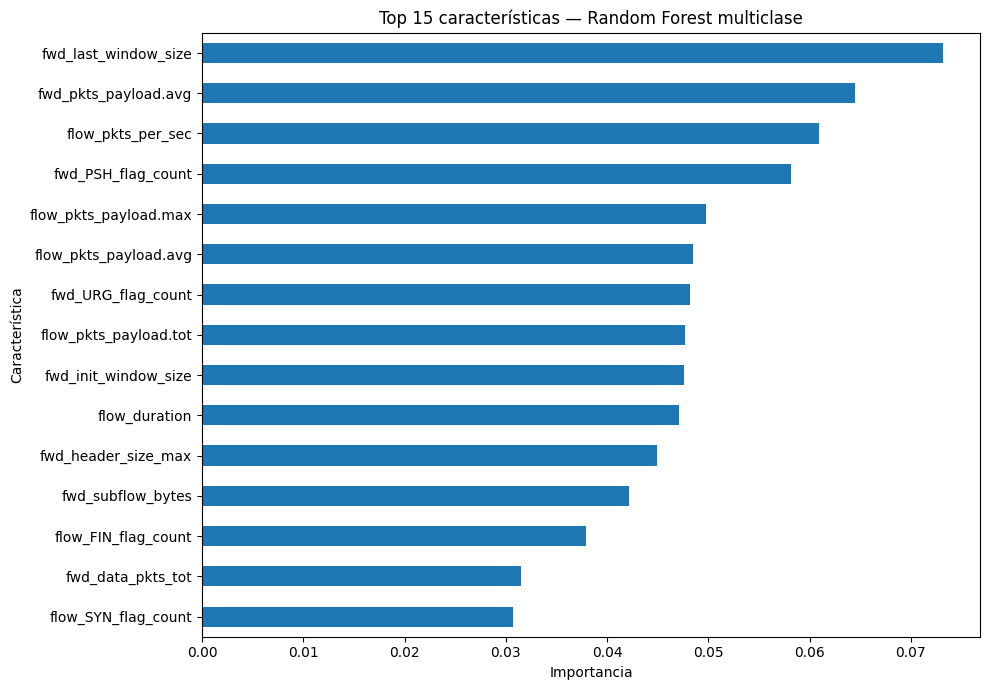

flow_duration: 0.047140 (4.71 %), posición 10


In [ ]:
importancias = pd.Series(
    rf_multiclase.feature_importances_, index=X_train.columns, name="Importancia"
).sort_values(ascending=False)
top15_importancias = importancias.head(15).rename_axis("Característica").reset_index()
top15_importancias["Porcentaje"] = top15_importancias["Importancia"] * 100
display(top15_importancias.style.format({
    "Importancia": "{:.6f}", "Porcentaje": "{:.2f}%"
}))

plt.figure(figsize=(10, 7))
importancias.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 características — Random Forest multiclase")
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

if "flow_duration" in importancias.index:
    importancia_flow_duration = float(importancias["flow_duration"])
    posicion_flow_duration = int(importancias.index.get_loc("flow_duration") + 1)
    print(f"flow_duration: {importancia_flow_duration:.6f} "
          f"({importancia_flow_duration*100:.2f} %), posición {posicion_flow_duration}")
else:
    importancia_flow_duration = None
    posicion_flow_duration = None
    print("flow_duration no está entre las features utilizadas.")

## 9. Comparación inicial con la clasificación binaria

Como referencia, el Random Forest binario reportó Accuracy = **0,997514** y F1-Macro = **0,996002**. La comparación es indicativa: el modelo binario distingue Normal/Ataque, mientras que el multiclase separa 12 tipos; además, cada partición estratifica con un objetivo distinto. F1-Macro permite observar mejor el rendimiento en clases minoritarias que el Accuracy por sí solo.

In [ ]:
referencia_binaria = {"Accuracy": 0.997514, "F1-Macro": 0.996002}
comparacion_binaria_multiclase = pd.DataFrame([
    {"Experimento": "Random Forest binario (referencia)",
     "Accuracy": referencia_binaria["Accuracy"], "F1-Macro": referencia_binaria["F1-Macro"]},
    {"Experimento": "Random Forest multiclase",
     "Accuracy": metricas["Accuracy"], "F1-Macro": metricas["F1-Macro"]},
])
display(comparacion_binaria_multiclase.style.format({
    "Accuracy": "{:.6f}", "F1-Macro": "{:.6f}"
}))

,Experimento,Accuracy,F1-Macro
0,Random Forest binario (referencia),0.997514,0.996002
1,Random Forest multiclase,0.996184,0.974786
